# 🤖 Machine Learning para Previsão de Preços — Etapa 2 (Analytics)

*Regressão Linear, Random Forest e XGBoost aplicados à previsão do preço de fechamento do dia seguinte*

Este notebook é a **Etapa 2 (Analytics)** do projeto de Análise de Ações da B3. Ele consome o dataset gerado na **Etapa 1 (ETL)** — o arquivo `acoes_b3_analytics.csv` — e aplica três modelos de Machine Learning para prever o preço de fechamento do próximo pregão.

---

## 1. Introdução

### 🎯 Objetivo
Prever o **preço de fechamento do dia seguinte** de cada ação, a partir das cotações e atributos derivados do dia atual (abertura, máxima, mínima, fechamento, volume, variação percentual, amplitude, retorno diário e média móvel de 20 dias), comparando três abordagens de Machine Learning:

1. **Regressão Linear** — modelo de referência (baseline), simples e interpretável;
2. **Random Forest** — ensemble de árvores de decisão, captura relações não lineares;
3. **XGBoost** — gradient boosting, geralmente o modelo com melhor desempenho em dados tabulares.

### 💼 Por que isso é útil
Prever o preço do próximo pregão com boa precisão é a base de qualquer estratégia quantitativa de curto prazo. Comparar um modelo simples (Regressão Linear) com modelos mais sofisticados (Random Forest e XGBoost) ajuda a entender se a complexidade adicional realmente se traduz em ganho de precisão — e a que custo (interpretabilidade, tempo de treino).

### 🛠️ Tecnologias Utilizadas
| Tecnologia | Papel no projeto |
|---|---|
| **Pandas** | Carregamento e preparação dos dados |
| **scikit-learn** | Regressão Linear, Random Forest e métricas de avaliação |
| **XGBoost** | Modelo de gradient boosting |
| **Matplotlib** | Visualização dos resultados |

> ⚠️ **Nota importante:** como o alvo escolhido é o **preço (nível)** do dia seguinte — e não o retorno percentual — espera-se que todos os modelos atinjam métricas de erro muito baixas e R² muito próximo de 1. Isso acontece porque o preço de fechamento de hoje já é, por si só, um excelente preditor do preço de fechamento de amanhã (preços de ações se movem como um "passeio aleatório" de curto prazo). Os resultados servem para comparar os modelos entre si — não devem ser interpretados como uma estratégia de investimento validada. Esse ponto é retomado na Seção 6 (Conclusões).

---

## 2. Importação das Bibliotecas e Carregamento dos Dados

Carregamos o CSV gerado na Etapa 1 (Seção 7.2 — *CSV para Analytics*). Esse arquivo já está limpo, padronizado e enriquecido com os atributos derivados (variação diária, amplitude, retorno diário e média móvel de 20 dias).

In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

In [0]:

df = spark.table("workspace.prata.table_acoes_b3").toPandas()
df = df.sort_values(["cd_empresa", "data"]).reset_index(drop=True)

print(f"Linhas: {len(df)} | Colunas: {len(df.columns)}")
df.head()

Linhas: 132902 | Colunas: 17


,data,empresa,setor,segmento,cd_empresa,Abertura,Maxima,Minima,Fechamento,Vol,variacao_dia_pct,amplitude,retorno_diario_pct,media_movel_20d,ano,mes,trimestre
0,2016-06-30,Banco ABC Brasil S.A.,Financeiro,Bancos Regionais,ABCB4.SA,6.034337,6.094357,5.909679,5.946615,108328,-1.45,0.18,None,5.95,2016,6,2
1,2016-07-01,Banco ABC Brasil S.A.,Financeiro,Bancos Regionais,ABCB4.SA,6.063914,6.151655,5.971298,6.093161,80078,0.48,0.18,2.46,6.02,2016,7,3
2,2016-07-04,Banco ABC Brasil S.A.,Financeiro,Bancos Regionais,ABCB4.SA,6.083412,6.151655,6.039541,6.098036,39985,0.24,0.11,0.08,6.05,2016,7,3
3,2016-07-05,Banco ABC Brasil S.A.,Financeiro,Bancos Regionais,ABCB4.SA,6.195527,6.327139,6.044417,6.117534,89011,-1.26,0.28,0.32,6.06,2016,7,3
4,2016-07-06,Banco ABC Brasil S.A.,Financeiro,Bancos Regionais,ABCB4.SA,6.117534,6.215024,6.044416,6.190652,98156,1.20,0.17,1.20,6.09,2016,7,3


## 3. Preparação dos Dados para Machine Learning

### 3.1 Criação da Variável-Alvo (Target)
O alvo é o preço de fechamento do **próximo** pregão de cada empresa. Usamos `shift(-1)` dentro de cada grupo (`cd_empresa`) — já ordenado por data — para "trazer" o fechamento do dia seguinte para a linha do dia atual. O último dia de cada empresa não tem "dia seguinte" disponível, por isso é descartado.

In [0]:
df["fechamento_d1"] = df.groupby("cd_empresa")["Fechamento"].shift(-1)

df_modelo = df.dropna(subset=["fechamento_d1"]).copy()
print(f"Linhas disponíveis para modelagem: {len(df_modelo)}")

Linhas disponíveis para modelagem: 132846


### 3.2 Seleção de Features e Tratamento de Variáveis Categóricas

Como features numéricas, usamos as cotações do dia atual e os atributos derivados na Etapa 1. Como variáveis categóricas, usamos `setor` (16 categorias) e o próprio ticker (`cd_empresa`) — o nível de preço varia muito de empresa para empresa, então saber **qual** ação é fundamental para prever o preço dela.

> 💡 A coluna `segmento` tem ~90 categorias diferentes — granularidade alta demais para *one-hot encoding* direto nesse projeto, então optamos por não incluí-la como feature.

In [0]:
features_numericas = [
    "Abertura", "Maxima", "Minima", "Fechamento", "Vol",
    "variacao_dia_pct", "amplitude", "retorno_diario_pct",
    "media_movel_20d", "ano", "mes", "trimestre"
]

features_categoricas = ["setor", "cd_empresa"]

df_encoded = pd.get_dummies(
    df_modelo[features_numericas + features_categoricas],
    columns=features_categoricas,
    drop_first=True
)

X = df_encoded
y = df_modelo["fechamento_d1"]

print(f"Total de features após encoding: {X.shape[1]}")

Total de features após encoding: 74


### 3.3 Divisão Treino / Teste — Split Temporal

Como os dados são uma **série temporal**, **não** podemos dividir treino e teste de forma aleatória — isso causaria *data leakage* (o modelo "veria" o futuro durante o treino). Em vez disso, usamos um corte por data: os 80% de pregões mais antigos formam o treino, e os 20% mais recentes formam o teste.

In [0]:
data_corte = df_modelo["data"].quantile(0.8)
print(f"Data de corte (80% mais antigo = treino): {data_corte.date()}")

treino_idx = df_modelo["data"] <= data_corte
teste_idx = df_modelo["data"] > data_corte

X_treino, X_teste = X[treino_idx], X[teste_idx]
y_treino, y_teste = y[treino_idx], y[teste_idx]

print(f"Treino: {len(X_treino)} linhas | Teste: {len(X_teste)} linhas")

Data de corte (80% mais antigo = treino): 2024-07-30
Treino: 106302 linhas | Teste: 26544 linhas


## 4. Modelos de Machine Learning

### 4.1 Regressão Linear (baseline)

In [0]:
print("NaN em X_treino:")
print(X_treino.isnull().sum())

print("\nNaN em y_treino:")
print(y_treino.isnull().sum())

print("\nTotal de NaN em X_treino:", X_treino.isnull().sum().sum())
print("Total de NaN em y_treino:", y_treino.isnull().sum())

# Remove as linhas com NaN em X_treino
X_treino = X_treino.dropna()

# Mantém apenas os mesmos índices em y_treino
y_treino = y_treino.loc[X_treino.index]

print("\nApós remover os NaN:")

print("NaN em X_treino:")
print(X_treino.isnull().sum())

print("\nNaN em y_treino:")
print(y_treino.isnull().sum())

print("\nTotal de NaN em X_treino:", X_treino.isnull().sum().sum())
print("Total de NaN em y_treino:", y_treino.isnull().sum())

NaN em X_treino:
Abertura               0
Maxima                 0
Minima                 0
Fechamento             0
Vol                    0
                      ..
cd_empresa_USIM3.SA    0
cd_empresa_USIM5.SA    0
cd_empresa_VALE3.SA    0
cd_empresa_VAMO3.SA    0
cd_empresa_YDUQ3.SA    0
Length: 74, dtype: int64

NaN em y_treino:
0

Total de NaN em X_treino: 56
Total de NaN em y_treino: 0

Após remover os NaN:
NaN em X_treino:
Abertura               0
Maxima                 0
Minima                 0
Fechamento             0
Vol                    0
                      ..
cd_empresa_USIM3.SA    0
cd_empresa_USIM5.SA    0
cd_empresa_VALE3.SA    0
cd_empresa_VAMO3.SA    0
cd_empresa_YDUQ3.SA    0
Length: 74, dtype: int64

NaN em y_treino:
0

Total de NaN em X_treino: 0
Total de NaN em y_treino: 0


In [0]:
modelo_lr = LinearRegression()
modelo_lr.fit(X_treino, y_treino)

pred_lr = modelo_lr.predict(X_teste)

### 4.2 Random Forest

Ensemble de árvores de decisão treinadas em subamostras dos dados; a previsão final é a média das previsões de todas as árvores. Captura relações não lineares entre as features sem precisar de transformação manual.

In [0]:
modelo_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
modelo_rf.fit(X_treino, y_treino)

pred_rf = modelo_rf.predict(X_teste)

### 4.3 XGBoost

Gradient boosting: as árvores são treinadas sequencialmente, cada uma corrigindo os erros da anterior. Costuma apresentar o melhor desempenho em dados tabulares, ao custo de mais hiperparâmetros para ajustar.

In [0]:
X_treino = X_treino.apply(pd.to_numeric, errors='coerce')
X_teste = X_teste.apply(pd.to_numeric, errors='coerce')

In [0]:
X_treino = X_treino.dropna()
y_treino = y_treino.loc[X_treino.index]

X_teste = X_teste.dropna()
y_teste = y_teste.loc[X_teste.index]

In [0]:
from xgboost import XGBRegressor

modelo_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(X_treino, y_treino)

pred_xgb = modelo_xgb.predict(X_teste)

## 5. Avaliação e Comparação dos Modelos

Comparamos os três modelos usando três métricas:

- **MAE** (Mean Absolute Error) — erro médio absoluto, em R$;
- **RMSE** (Root Mean Squared Error) — penaliza mais os erros grandes, também em R$;
- **R²** (coeficiente de determinação) — quanto da variação do preço o modelo explica (1 = perfeito).

In [0]:
def avaliar(nome, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return {"modelo": nome, "MAE": round(mae, 3), "RMSE": round(rmse, 3), "R2": round(r2, 4)}

resultados = pd.DataFrame([
    avaliar("Regressão Linear", y_teste, pred_lr),
    avaliar("Random Forest", y_teste, pred_rf),
    avaliar("XGBoost", y_teste, pred_xgb),
])

resultados

,modelo,MAE,RMSE,R2
0,Regressão Linear,0.225,0.451,0.9992
1,Random Forest,0.142,0.374,0.9994
2,XGBoost,0.311,0.962,0.9962


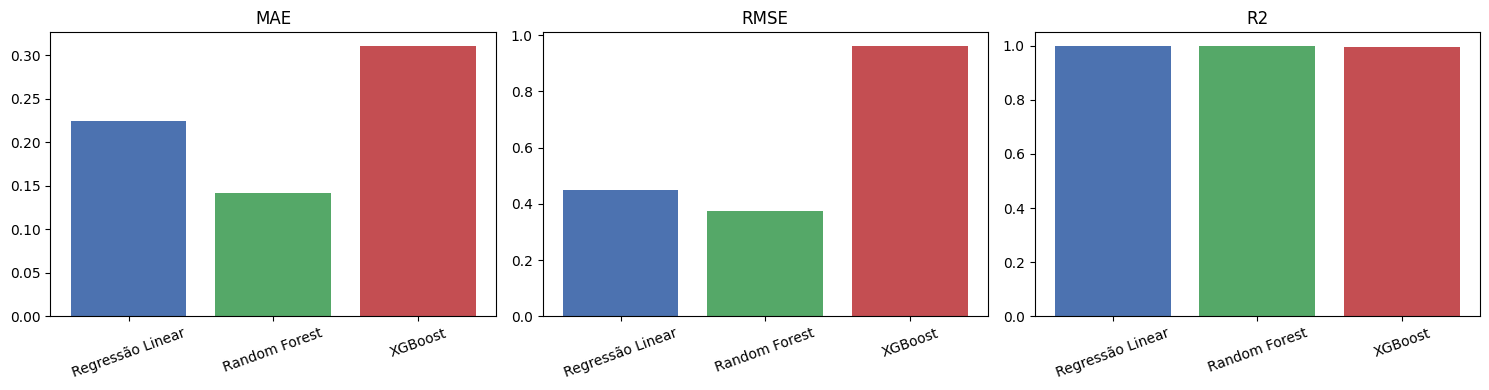

In [0]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cores = ["#4C72B0", "#55A868", "#C44E52"]

for ax, metrica in zip(axes, ["MAE", "RMSE", "R2"]):
    ax.bar(resultados["modelo"], resultados[metrica], color=cores)
    ax.set_title(metrica)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Importância das Features

Quais variáveis mais influenciaram a previsão em cada modelo de árvore?

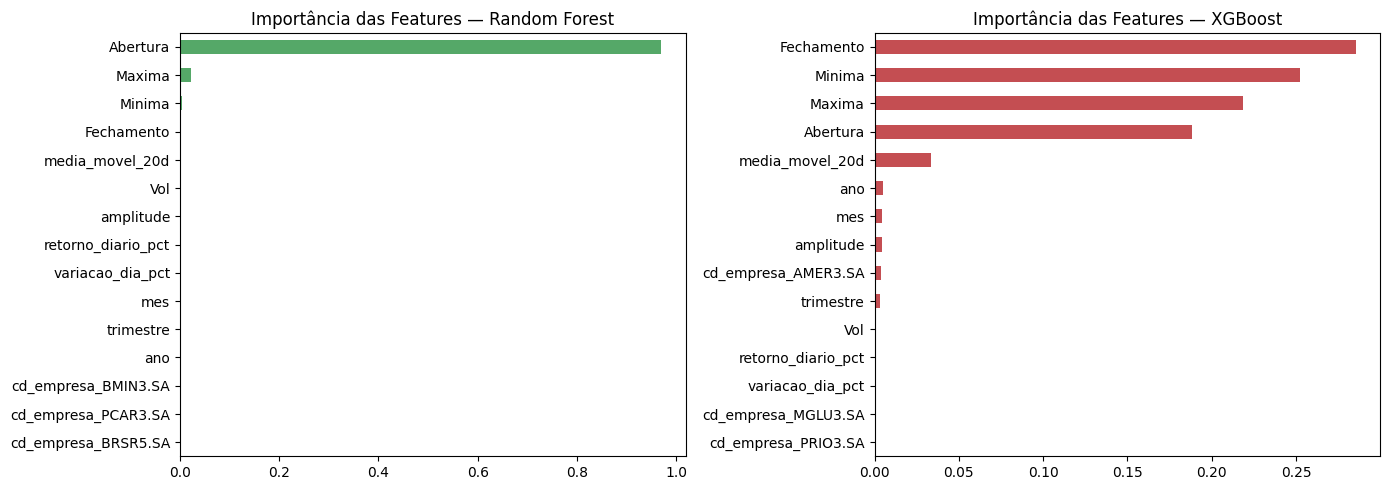

In [0]:
importancias_rf = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
importancias_xgb = pd.Series(modelo_xgb.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

importancias_rf.plot(kind="barh", ax=axes[0], color="#55A868")
axes[0].set_title("Importância das Features — Random Forest")
axes[0].invert_yaxis()

importancias_xgb.plot(kind="barh", ax=axes[1], color="#C44E52")
axes[1].set_title("Importância das Features — XGBoost")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### Preço Real vs. Previsto — Exemplo de uma Empresa

Para inspecionar visualmente a qualidade das previsões, comparamos o preço real e o preço previsto (Random Forest e XGBoost) para a empresa com mais registros no conjunto de teste.

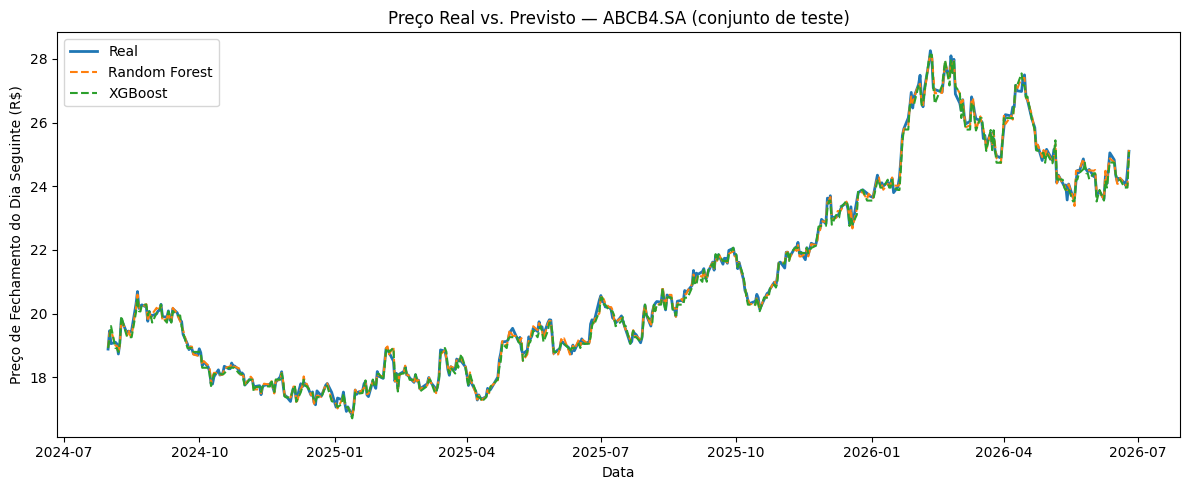

In [0]:
df_teste = df_modelo.loc[teste_idx].copy()
df_teste["pred_lr"] = pred_lr
df_teste["pred_rf"] = pred_rf
df_teste["pred_xgb"] = pred_xgb

ticker_exemplo = df_teste["cd_empresa"].value_counts().idxmax()
exemplo = df_teste[df_teste["cd_empresa"] == ticker_exemplo].sort_values("data")

plt.figure(figsize=(12, 5))
plt.plot(exemplo["data"], exemplo["fechamento_d1"], label="Real", linewidth=2)
plt.plot(exemplo["data"], exemplo["pred_rf"], label="Random Forest", linestyle="--")
plt.plot(exemplo["data"], exemplo["pred_xgb"], label="XGBoost", linestyle="--")
plt.title(f"Preço Real vs. Previsto — {ticker_exemplo} (conjunto de teste)")
plt.xlabel("Data")
plt.ylabel("Preço de Fechamento do Dia Seguinte (R$)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Conclusões

Este notebook concluiu a **Etapa 2 (Analytics)** do projeto: a partir do dataset tratado na Etapa 1, treinamos e comparamos três modelos de Machine Learning para prever o preço de fechamento do próximo pregão.

### Principais pontos
- Os três modelos tendem a apresentar **R² muito alto** e erros baixos — isso é esperado e **não** significa, por si só, que o modelo "bate o mercado". Preços de fechamento consecutivos são fortemente correlacionados (o preço de hoje já carrega a maior parte da informação sobre o preço de amanhã);
- A real comparação de valor entre Regressão Linear, Random Forest e XGBoost aparece nas métricas relativas entre eles (qual erra menos) e na importância das features — não no valor absoluto do R²;
- O split temporal (em vez de aleatório) foi essencial para uma avaliação honesta: ele simula a situação real, em que o modelo só tem acesso ao passado no momento da previsão.

### Limitações
- Prever o **nível de preço** é um problema mais "fácil" e menos informativo para decisão de investimento do que prever o **retorno** (variação percentual) — que reflete diretamente o ganho ou perda do investidor e é o problema clássico (e muito mais desafiador) em finanças quantitativas;
- Não foi feita otimização de hiperparâmetros (ex.: `GridSearchCV`/`RandomizedSearchCV`) nem validação cruzada com múltiplas janelas temporais (*walk-forward validation*);
- O modelo é único para todas as empresas (*pooled*); modelos específicos por ação ou por setor podem capturar dinâmicas próprias de cada papel.

### Próximos passos sugeridos
- Repetir esse pipeline prevendo **`retorno_diario_pct`** do dia seguinte em vez do preço — um teste mais rigoroso da capacidade preditiva real dos modelos;
- Aplicar *walk-forward validation* (múltiplas janelas de treino/teste ao longo do tempo) em vez de um único corte;
- Buscar os melhores hiperparâmetros com `GridSearchCV` ou `Optuna`;
- Adicionar indicadores técnicos como features (RSI, MACD, Bandas de Bollinger);
- Avaliar o resultado em termos financeiros: simular uma estratégia de compra/venda baseada nas previsões e medir o retorno acumulado (*backtesting*) — e não apenas métricas estatísticas como MAE/RMSE/R².